# Downstream results

Every evaluation record in `results/records` (ingested into `results/experiments.sqlite`), one table per task.

* **score**: test metric with bootstrap 95% CI, for the head picked on **validation** (`picked on = test!` means the task had no validation score).
* **Δ random**: test minus the random-init encoder (`random_small`) on the same task — the floor every pretrained model must beat.
* **pretrain overlap**: share of the task's volumes that were in the (unlabelled) pretraining pool.

Re-run from the top to pick up new records. Helpers live in `brain/downstream/results_view.py`.

In [11]:
import sys
from pathlib import Path

# make the repo importable whatever the kernel's working directory or environment
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "brain" / "__init__.py").exists()),
            Path("/home/roku/brain-model"))
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from brain.downstream import results_view as rv

pd.set_option("display.max_colwidth", 60)
rep = rv.load(ingest=True)          # folds new record files into the database first
MODELS = None                       # e.g. ["random_small (final)", "cls_s42 @15k", "cls_reg4_s42 @15k"]
if MODELS:
    rep = rep[rep.model.isin(MODELS)]
display(rep.groupby("model").task.nunique().rename("tasks scored").to_frame())

,tasks scored
model,
cls_reg4_s42 @15k,13
cls_s42 @15k,14
mae3d_base_s42 @920,14
mae3d_small_v2_s42 @30k,25
mt_nolabels_s42 @18k,18
mt_synthseg_s42 @17k,23
mt_v3init_s42 @15k,22
none_s42 @15k,13
random_small (final),30


## Model subset

`label-seen` (per-task tables) marks tasks a label-trained model (multitask) has seen: `labels` = that task's own labels; `task` = the same target from other cohorts. `rv.overview(rep, hide_seen="labels")` blanks the former, `hide_seen="task"` both.


In [12]:
# Which models to show: glob patterns on the model labels (all names: sorted(rep_all.model.unique())).
# keep=None shows every model not dropped; random-init baselines stay unless dropped explicitly.
KEEP = None                      # e.g. ["v3_cls_s42 @18k", "mae3d_small_v2*", "mt_*"]
DROP = [
    # "cls_reg4_s42*", "cls_s42 @15k", "none_s42*",       # prefix ablation arms (v3 chose cls)
    # "v2_cls_s42*", "v3_cls_s42 @16k",                    # superseded checkpoints
    # "v3_cls_s42_tiled*", "v3_cls_s42_b4*", "random_small_tiled*",   # context / early-layer diagnostics
    # "mae3d_base_s42*",                                   # MAE v1 (stopped at 920)
]
rep_all = rep
rep = rv.select(rep_all)
print(sorted(rep.model.unique()))

['cls_reg4_s42 @15k', 'cls_s42 @15k', 'mae3d_base_s42 @920', 'mae3d_small_v2_s42 @30k', 'mt_nolabels_s42 @18k', 'mt_synthseg_s42 @17k', 'mt_v3init_s42 @15k', 'none_s42 @15k', 'random_small (final)', 'random_small_tiled (final)', 'v2_cls_s42 @16k', 'v3_cls_s42 @16k', 'v3_cls_s42 @18k', 'v3_cls_s42_b4final @18k', 'v3_cls_s42_b4only @18k', 'v3_cls_s42_tiled @18k']


## Overview: test scores

In [13]:
rv.overview(rep)

## Overview: gain over random-init

In [7]:
rv.overview(rep, delta=True)

## Per task

### classification

#### `abide_asd`

,model,auc,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_synthseg_s42 @17k,"0.643 [0.553, 0.726]",+0.062,tok_conv,val,100%,
1,mt_v3init_s42 @15k,"0.611 [0.522, 0.693]",+0.030,tok_conv,val,100%,
2,none_s42 @15k,"0.609 [0.524, 0.695]",+0.028,tok_conv,val,100%,
3,cls_reg4_s42 @15k,"0.599 [0.512, 0.683]",+0.019,tok_conv,val,100%,
4,mt_nolabels_s42 @18k,"0.587 [0.496, 0.682]",+0.007,pca_global_logreg,val,100%,
5,random_small (final),"0.581 [0.491, 0.665]",+0.000,tok_conv,val,100%,
6,mae3d_base_s42 @920,"0.568 [0.478, 0.653]",-0.012,tok_conv,val,100%,
7,v3_cls_s42 @18k,"0.567 [0.480, 0.653]",-0.013,tok_conv,val,100%,
8,cls_s42 @15k,"0.567 [0.477, 0.651]",-0.014,tok_conv,val,100%,
9,v2_cls_s42 @16k,"0.560 [0.472, 0.643]",-0.021,tok_conv,val,100%,


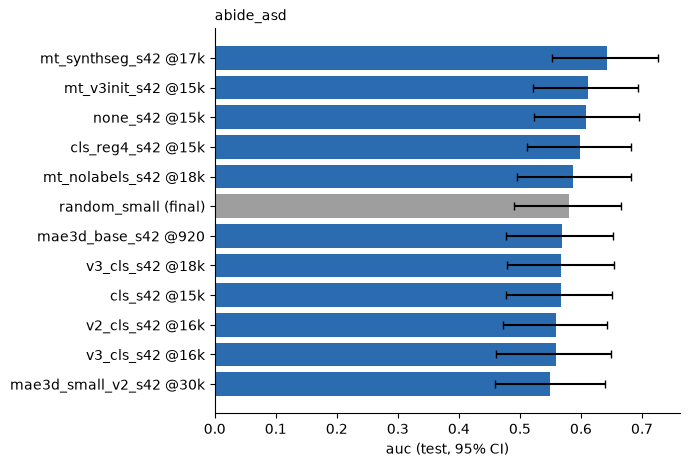

#### `cq500`

,model,auc_ovr_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,none_s42 @15k,"0.874 [0.820, 0.919]",+0.083,tok_conv,val,0%,
1,v2_cls_s42 @16k,"0.866 [0.817, 0.906]",+0.075,cls_logreg,val,0%,
2,v3_cls_s42 @18k,"0.865 [0.811, 0.911]",+0.074,cls_logreg,val,0%,
3,v3_cls_s42_b4final @18k,"0.865 [0.811, 0.911]",+0.074,cls_logreg,val,0%,
4,mt_synthseg_s42 @17k,"0.864 [0.811, 0.914]",+0.073,slots_logreg,val,0%,task
5,cls_s42 @15k,"0.863 [0.812, 0.907]",+0.072,cls_logreg,val,0%,
6,v3_cls_s42_tiled @18k,"0.849 [0.782, 0.898]",+0.058,tok_conv,val,0%,
7,mt_nolabels_s42 @18k,"0.844 [0.787, 0.892]",+0.053,slots_logreg,val,0%,task
8,mae3d_small_v2_s42 @30k,"0.843 [0.784, 0.889]",+0.052,tok_conv,val,0%,
9,mt_v3init_s42 @15k,"0.833 [0.775, 0.880]",+0.042,cls_logreg,val,0%,task


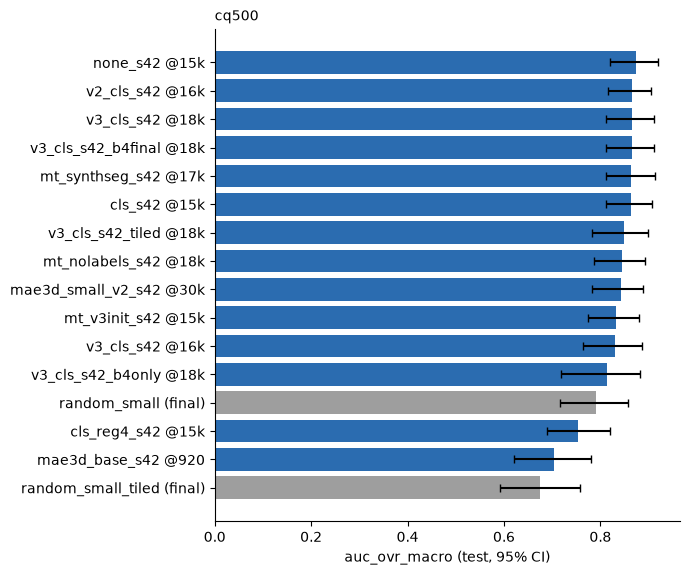

#### `msd`

,model,auc,Δ random,head,picked on,pretrain overlap,label-seen
0,v3_cls_s42 @18k,"0.978 [0.940, 1.000]",+0.130,tok_conv,val,0%,
1,mt_nolabels_s42 @18k,"0.968 [0.929, 0.995]",+0.120,tok_conv,val,0%,task
2,mt_synthseg_s42 @17k,"0.965 [0.918, 0.998]",+0.118,tok_conv,val,0%,task
3,v3_cls_s42 @16k,"0.956 [0.898, 0.992]",+0.109,tok_conv,val,0%,
4,v3_cls_s42_tiled @18k,"0.947 [0.890, 0.986]",+0.100,tok_conv,val,0%,
5,v3_cls_s42_b4final @18k,"0.925 [0.845, 0.979]",+0.078,tok_conv,val,0%,
6,mae3d_small_v2_s42 @30k,"0.925 [0.852, 0.982]",+0.078,plane_logreg,val,0%,
7,v3_cls_s42_b4only @18k,"0.923 [0.856, 0.973]",+0.076,tok_conv,val,0%,
8,mt_v3init_s42 @15k,"0.881 [0.801, 0.954]",+0.034,cls_logreg,val,0%,task
9,cls_reg4_s42 @15k,"0.879 [0.794, 0.951]",+0.031,tok_conv,val,0%,


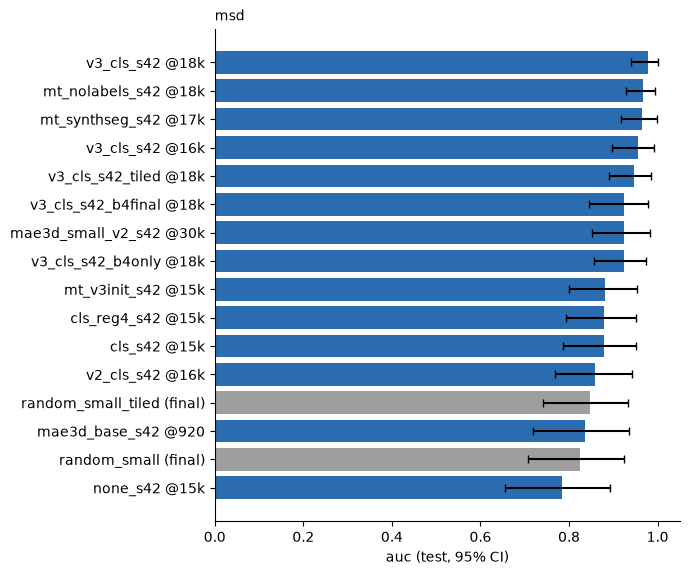

#### `oasis1_cdr`

,model,auc,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_synthseg_s42 @17k,"0.799 [0.658, 0.937]",+0.118,pca_global_logreg,val,100%,
1,mt_nolabels_s42 @18k,"0.767 [0.609, 0.908]",+0.086,plane_logreg,val,100%,
2,mt_v3init_s42 @15k,"0.762 [0.599, 0.899]",+0.080,grid_logreg,val,100%,
3,cls_s42 @15k,"0.749 [0.580, 0.888]",+0.067,grid_logreg,val,100%,
4,none_s42 @15k,"0.730 [0.551, 0.890]",+0.048,grid_logreg,val,100%,
5,mae3d_small_v2_s42 @30k,"0.719 [0.535, 0.882]",+0.037,plane_logreg,val,100%,
6,v3_cls_s42 @16k,"0.719 [0.547, 0.874]",+0.037,plane_logreg,val,100%,
7,v3_cls_s42 @18k,"0.701 [0.529, 0.853]",+0.019,grid_logreg,val,100%,
8,random_small (final),"0.682 [0.497, 0.840]",+0.000,pca_global_logreg,val,100%,
9,random_small_tiled (final),"0.660 [0.472, 0.834]",-0.021,grid_logreg,val,100%,


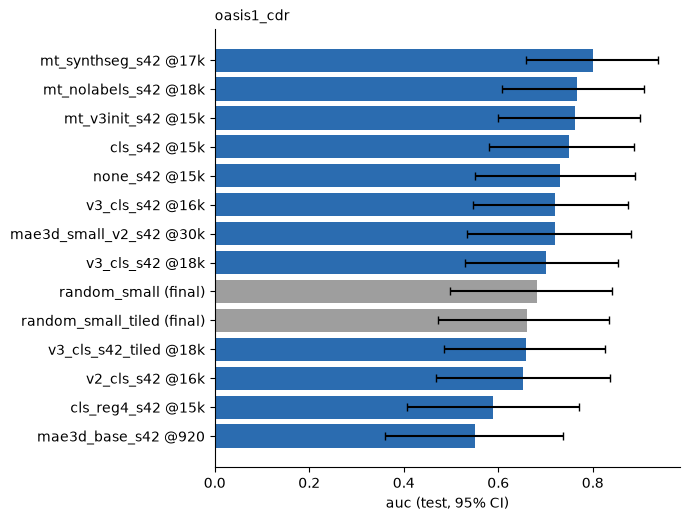

#### `oasis2_cdr`

,model,auc,Δ random,head,picked on,pretrain overlap,label-seen
0,mae3d_small_v2_s42 @30k,"0.719 [0.631, 0.801]",+0.007,plane_logreg,val,40%,
1,random_small (final),"0.712 [0.628, 0.790]",+0.000,pca_global_logreg,val,40%,
2,none_s42 @15k,"0.712 [0.619, 0.796]",-0.000,pca_global_logreg,val,40%,
3,v3_cls_s42_tiled @18k,"0.711 [0.624, 0.786]",-0.001,grid_logreg,val,40%,
4,mt_v3init_s42 @15k,"0.702 [0.607, 0.787]",-0.011,tok_conv,val,40%,
5,mt_nolabels_s42 @18k,"0.695 [0.609, 0.777]",-0.018,plane_logreg,val,40%,
6,v3_cls_s42 @18k,"0.687 [0.598, 0.772]",-0.025,grid_logreg,val,40%,
7,v3_cls_s42_b4final @18k,"0.679 [0.589, 0.767]",-0.034,grid_logreg,val,40%,
8,v3_cls_s42 @16k,"0.678 [0.584, 0.766]",-0.034,grid_logreg,val,40%,
9,mae3d_base_s42 @920,"0.678 [0.591, 0.767]",-0.034,plane_logreg,val,40%,


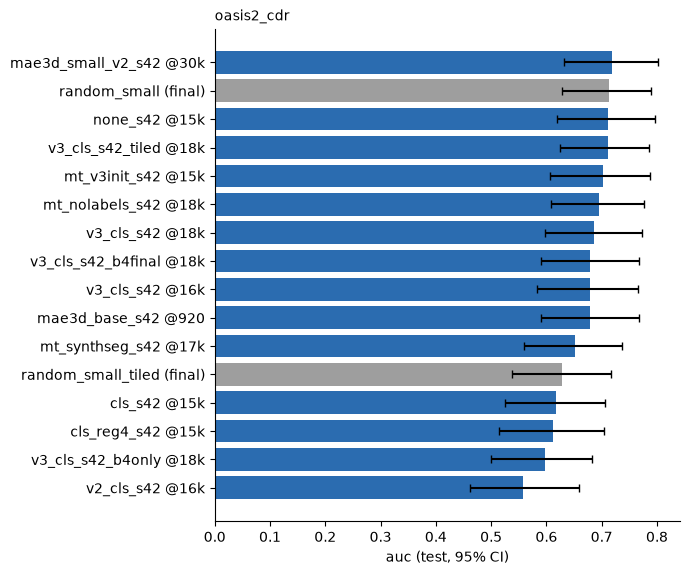

#### `oasis2_conversion`

,model,auc,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_nolabels_s42 @18k,"0.704 [0.467, 0.920]",+0.261,taskout_logreg,val,100%,
1,none_s42 @15k,"0.635 [0.301, 0.974]",+0.191,plane_logreg,val,100%,
2,cls_s42 @15k,"0.617 [0.216, 0.959]",+0.174,grid_logreg,val,100%,
3,mt_synthseg_s42 @17k,"0.496 [0.115, 0.876]",+0.052,tok_conv,val,100%,
4,random_small (final),"0.443 [0.160, 0.741]",+0.000,tok_conv,val,100%,
5,mt_v3init_s42 @15k,"0.417 [0.122, 0.750]",-0.026,tok_conv,val,100%,
6,mae3d_base_s42 @920,"0.261 [0.067, 0.511]",-0.183,tok_conv,val,100%,
7,v3_cls_s42 @16k,"0.235 [0.000, 0.469]",-0.209,tok_conv,val,100%,
8,mae3d_small_v2_s42 @30k,"0.226 [0.000, 0.642]",-0.217,tok_conv,val,100%,
9,v3_cls_s42 @18k,"0.209 [0.000, 0.447]",-0.235,tok_conv,val,100%,


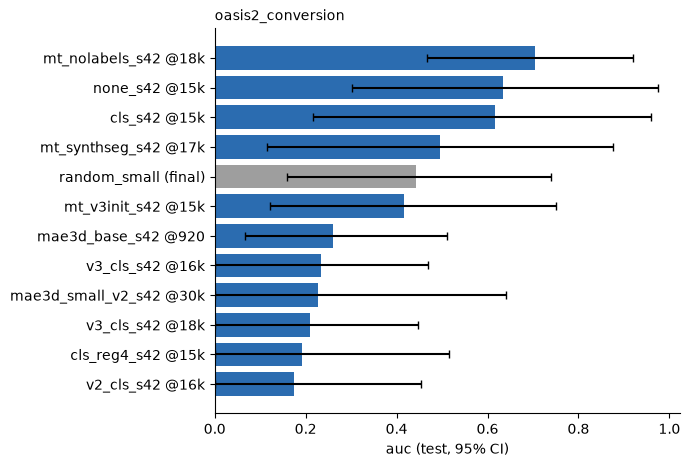

### regression

#### `id1000_age`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,random_small (final),"0.180 [0.065, 0.269]",+0.000,plane_ridge,val,100%,
1,mae3d_small_v2_s42 @30k,"0.150 [0.033, 0.240]",-0.030,tok_conv,val,100%,
2,v3_cls_s42 @18k,"0.149 [-0.013, 0.275]",-0.031,cls_ridge,val,100%,
3,mt_synthseg_s42 @17k,"0.139 [-0.039, 0.279]",-0.042,cls_ridge,val,100%,task
4,random_small_tiled (final),"0.129 [-0.029, 0.251]",-0.052,plane_ridge,val,100%,
5,v3_cls_s42 @16k,"0.127 [0.002, 0.223]",-0.053,tok_conv,val,100%,
6,mt_v3init_s42 @15k,"0.111 [-0.032, 0.236]",-0.069,tok_conv,val,100%,task
7,mt_nolabels_s42 @18k,"0.078 [-0.048, 0.180]",-0.103,tok_conv,val,100%,task
8,v3_cls_s42_tiled @18k,"0.068 [-0.045, 0.153]",-0.113,tok_conv,val,100%,
9,v2_cls_s42 @16k,"0.042 [-0.065, 0.118]",-0.138,tok_conv,val,100%,


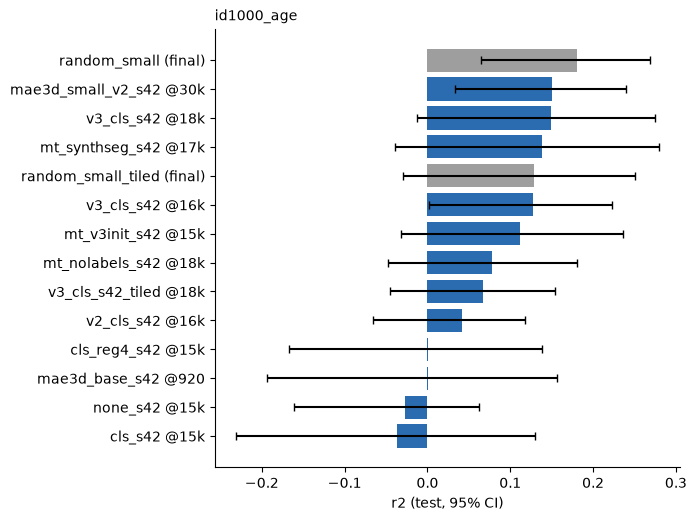

#### `ixi_age`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_v3init_s42 @15k,"0.859 [0.788, 0.905]",+0.132,cls_ridge,val,100%,task
1,mt_synthseg_s42 @17k,"0.859 [0.783, 0.907]",+0.132,tok_conv,val,100%,task
2,v3_cls_s42 @16k,"0.844 [0.777, 0.888]",+0.117,tok_conv,val,100%,
3,v3_cls_s42 @18k,"0.843 [0.769, 0.891]",+0.116,tok_conv,val,100%,
4,mt_nolabels_s42 @18k,"0.843 [0.765, 0.897]",+0.116,tok_conv,val,100%,task
5,v3_cls_s42_b4final @18k,"0.830 [0.749, 0.879]",+0.103,tok_conv,val,100%,
6,cls_reg4_s42 @15k,"0.808 [0.726, 0.864]",+0.081,tok_conv,val,100%,
7,v2_cls_s42 @16k,"0.801 [0.708, 0.859]",+0.074,tok_conv,val,100%,
8,cls_s42 @15k,"0.788 [0.691, 0.848]",+0.061,tok_conv,val,100%,
9,v3_cls_s42_tiled @18k,"0.763 [0.668, 0.828]",+0.036,grid_ridge,val,100%,


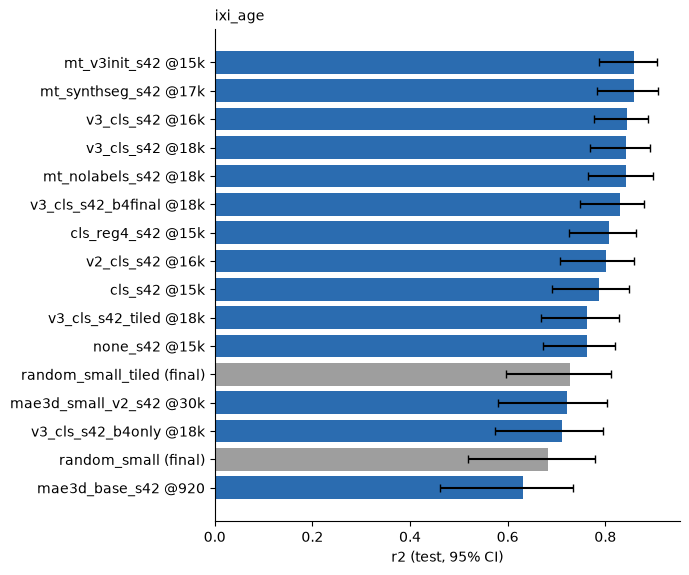

#### `ms3seg_age`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,mae3d_small_v2_s42 @30k,"0.387 [0.170, 0.474]",+0.011,tok_conv,val,0%,
1,mt_v3init_s42 @15k,"0.386 [0.202, 0.535]",+0.011,tok_conv,val,0%,task
2,mae3d_base_s42 @920,"0.384 [0.249, 0.469]",+0.009,plane_ridge,val,0%,
3,mt_synthseg_s42 @17k,"0.383 [0.136, 0.495]",+0.008,tok_conv,val,0%,task
4,mt_nolabels_s42 @18k,"0.381 [0.181, 0.492]",+0.006,tok_conv,val,0%,task
5,random_small_tiled (final),"0.375 [0.162, 0.464]",+0.000,plane_ridge,val,0%,
6,random_small (final),"0.366 [0.177, 0.473]",-0.010,plane_ridge,val,0%,
7,v3_cls_s42_b4final @18k,"0.338 [0.150, 0.484]",-0.037,tok_conv,val,0%,
8,v3_cls_s42 @16k,"0.319 [0.139, 0.425]",-0.056,grid_ridge,val,0%,
9,v3_cls_s42_b4only @18k,"0.311 [0.136, 0.431]",-0.064,tok_conv,val,0%,


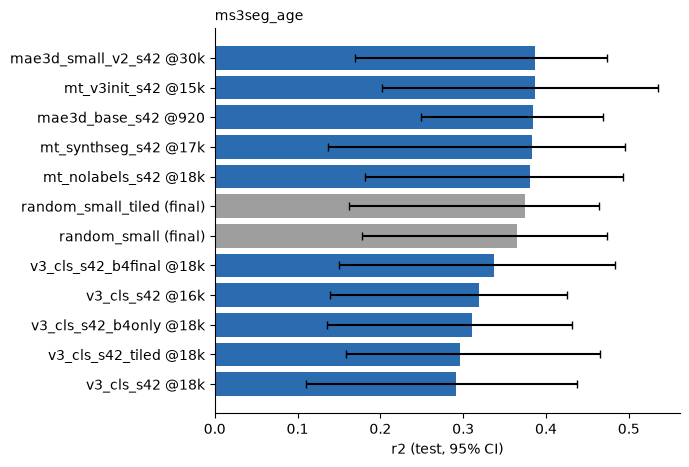

#### `oasis1_age`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,v3_cls_s42_tiled @18k,"0.923 [0.890, 0.948]",+0.068,tok_conv,val,95%,
1,mt_nolabels_s42 @18k,"0.921 [0.885, 0.948]",+0.066,tok_conv,val,95%,task
2,mt_synthseg_s42 @17k,"0.920 [0.888, 0.945]",+0.065,cls_ridge,val,95%,task
3,none_s42 @15k,"0.920 [0.887, 0.944]",+0.064,tok_conv,val,95%,
4,v3_cls_s42 @16k,"0.883 [0.836, 0.915]",+0.028,tok_conv,val,95%,
5,cls_s42 @15k,"0.882 [0.839, 0.915]",+0.027,tok_conv,val,95%,
6,mt_v3init_s42 @15k,"0.882 [0.827, 0.919]",+0.026,tok_conv,val,95%,task
7,v3_cls_s42 @18k,"0.877 [0.836, 0.909]",+0.022,cls_ridge,val,95%,
8,v3_cls_s42_b4final @18k,"0.877 [0.836, 0.909]",+0.022,cls_ridge,val,95%,
9,v2_cls_s42 @16k,"0.873 [0.821, 0.908]",+0.017,tok_conv,val,95%,


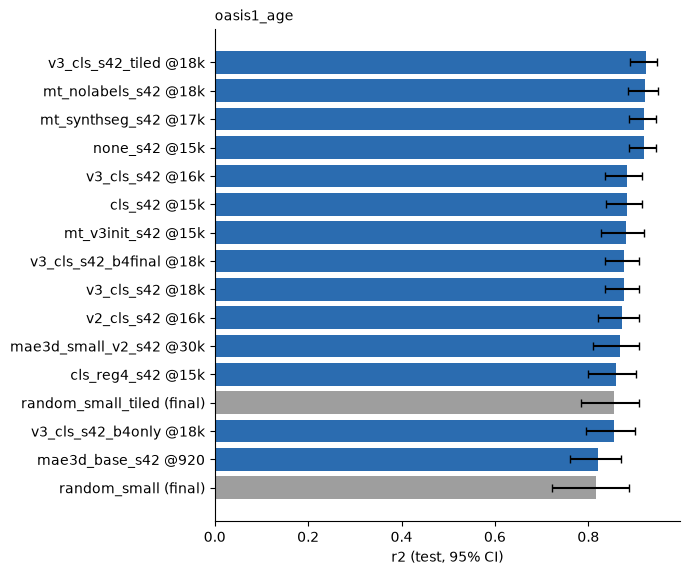

#### `piop1_age`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,random_small (final),"0.060 [-0.267, 0.194]",+0.000,grid_ridge,val,100%,
1,mt_synthseg_s42 @17k,"0.054 [-0.380, 0.248]",-0.005,grid_ridge,val,100%,task
2,mt_v3init_s42 @15k,"0.049 [-0.286, 0.184]",-0.011,plane_ridge,val,100%,task
3,v2_cls_s42 @16k,"0.009 [-0.371, 0.184]",-0.050,grid_ridge,val,100%,
4,mae3d_base_s42 @920,"-0.005 [-0.367, 0.156]",-0.065,grid_ridge,val,100%,
5,cls_s42 @15k,"-0.029 [-0.489, 0.193]",-0.089,grid_ridge,val,100%,
6,v3_cls_s42 @16k,"-0.032 [-0.496, 0.170]",-0.091,cls_ridge,val,100%,
7,none_s42 @15k,"-0.034 [-0.475, 0.152]",-0.094,grid_ridge,val,100%,
8,mt_nolabels_s42 @18k,"-0.042 [-0.520, 0.175]",-0.102,pca_global_ridge,val,100%,task
9,v3_cls_s42 @18k,"-0.052 [-0.509, 0.160]",-0.112,grid_ridge,val,100%,


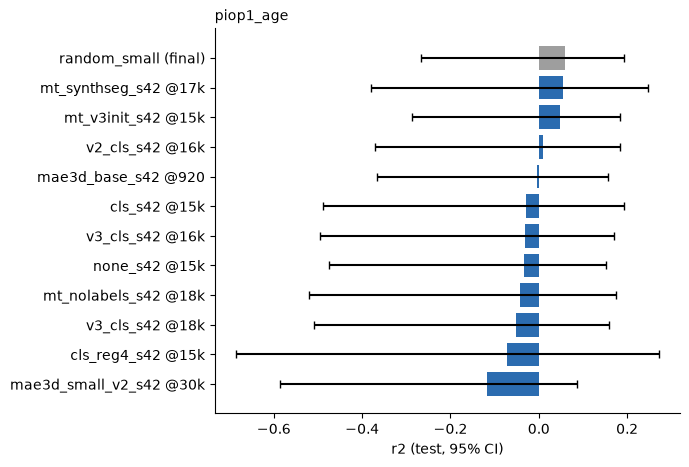

#### `piop2_age`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_synthseg_s42 @17k,"-0.053 [-0.502, 0.107]",+0.414,cls_ridge,val,100%,task
1,v3_cls_s42 @16k,"-0.068 [-0.511, 0.142]",+0.399,grid_ridge,val,100%,
2,v3_cls_s42 @18k,"-0.099 [-0.598, 0.161]",+0.368,grid_ridge,val,100%,
3,cls_s42 @15k,"-0.130 [-0.576, 0.097]",+0.337,cls_ridge,val,100%,
4,cls_reg4_s42 @15k,"-0.133 [-0.590, 0.013]",+0.334,cls_ridge,val,100%,
5,mae3d_small_v2_s42 @30k,"-0.178 [-0.591, 0.043]",+0.289,grid_ridge,val,100%,
6,v2_cls_s42 @16k,"-0.182 [-0.590, -0.002]",+0.285,grid_ridge,val,100%,
7,mt_nolabels_s42 @18k,"-0.189 [-0.535, 0.006]",+0.278,tok_conv,val,100%,task
8,mt_v3init_s42 @15k,"-0.234 [-0.794, 0.046]",+0.233,tok_conv,val,100%,task
9,mae3d_base_s42 @920,"-0.315 [-0.916, 0.034]",+0.152,grid_ridge,val,100%,


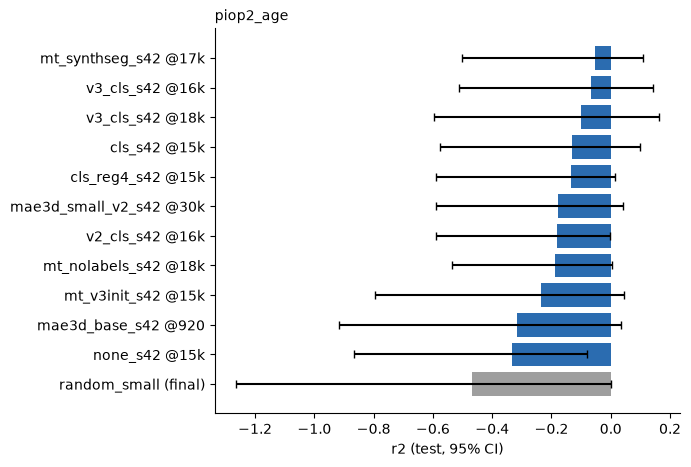

#### `pixar_age`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,mae3d_small_v2_s42 @30k,"0.925 [0.881, 0.958]",+0.029,tok_conv,val,100%,
1,cls_reg4_s42 @15k,"0.914 [0.856, 0.953]",+0.018,tok_conv,val,100%,
2,random_small (final),"0.897 [0.801, 0.941]",+0.000,tok_conv,val,100%,
3,random_small_tiled (final),"0.890 [0.781, 0.940]",-0.007,tok_conv,val,100%,
4,mt_v3init_s42 @15k,"0.865 [0.646, 0.950]",-0.031,grid_ridge,val,100%,task
5,mt_synthseg_s42 @17k,"0.849 [0.766, 0.922]",-0.048,tok_conv,val,100%,task
6,mae3d_base_s42 @920,"0.840 [0.685, 0.898]",-0.057,plane_ridge,val,100%,
7,mt_nolabels_s42 @18k,"0.829 [0.604, 0.935]",-0.067,plane_ridge,val,100%,task
8,cls_s42 @15k,"0.827 [0.605, 0.910]",-0.070,grid_ridge,val,100%,
9,v3_cls_s42_b4only @18k,"0.826 [0.530, 0.919]",-0.070,tok_conv,val,100%,


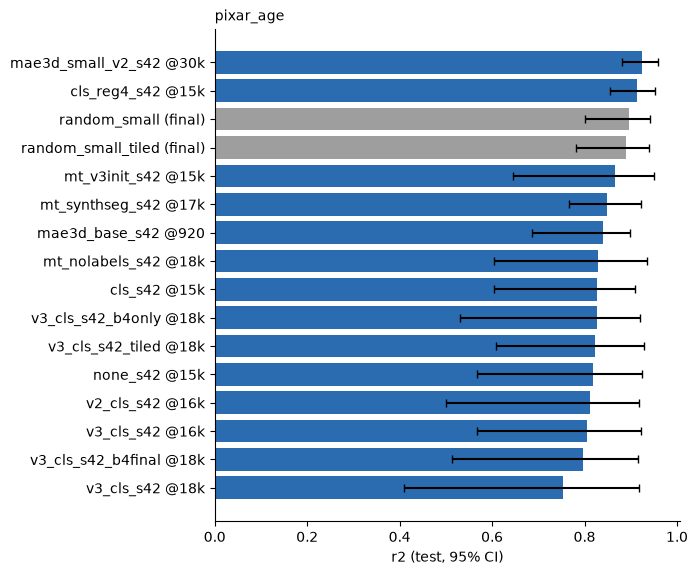

#### `valdo_epvs`

,model,r2,Δ random,head,picked on,pretrain overlap,label-seen
0,v3_cls_s42 @16k,"0.300 [-0.030, 0.520]",+0.056,cls_ridge,val,0%,
1,random_small_tiled (final),"0.244 [-0.069, 0.400]",+0.000,plane_ridge,val,0%,
2,mae3d_base_s42 @920,"0.242 [-0.091, 0.347]",-0.002,plane_ridge,val,0%,
3,random_small (final),"0.233 [-0.041, 0.399]",-0.012,plane_ridge,val,0%,
4,v3_cls_s42_b4only @18k,"0.218 [-0.140, 0.359]",-0.027,grid_ridge,val,0%,
5,v3_cls_s42 @18k,"0.141 [-0.207, 0.277]",-0.103,cls_ridge,val,0%,
6,v3_cls_s42_b4final @18k,"0.141 [-0.207, 0.277]",-0.103,cls_ridge,val,0%,
7,mae3d_small_v2_s42 @30k,"0.055 [-0.558, 0.125]",-0.189,grid_ridge,val,0%,
8,mt_synthseg_s42 @17k,"0.021 [-0.405, 0.222]",-0.223,tok_conv,val,0%,
9,v3_cls_s42_tiled @18k,"0.018 [-0.449, 0.162]",-0.227,grid_ridge,val,0%,


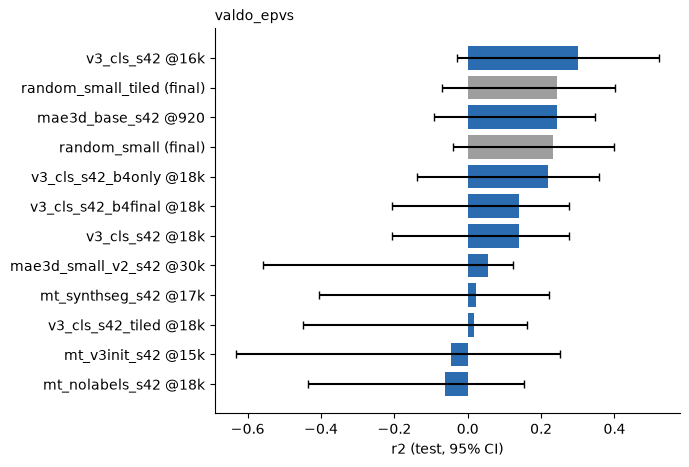

### segmentation

#### `aisd`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,random_small (final),"0.221 [0.159, 0.289]",+0.000,tok_unet3d,val,0%,
1,mae3d_small_v2_s42 @30k,"0.208 [0.163, 0.258]",-0.013,tok_unet3d,val,0%,


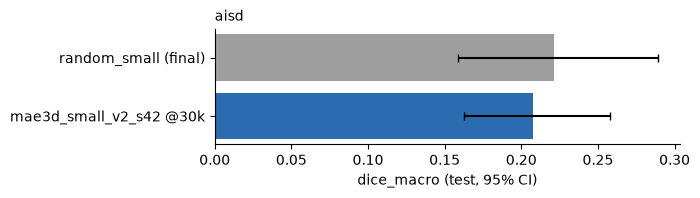

#### `atlas`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,mae3d_small_v2_s42 @30k,"0.367 [0.328, 0.407]",+0.247,tok_unet3d,val,0%,
1,v3_cls_s42 @18k,"0.323 [0.284, 0.361]",+0.203,tok_unet3d,val,0%,
2,v3_cls_s42_b4final @18k,"0.315 [0.277, 0.354]",+0.195,tok_unet3d,val,0%,
3,mt_synthseg_s42 @17k,"0.314 [0.276, 0.353]",+0.194,tok_unet3d,val,0%,
4,cls_s42 @15k,"0.274 [0.239, 0.310]",+0.154,tok_unet3d,val,0%,
5,mt_v3init_s42 @15k,"0.249 [0.213, 0.284]",+0.128,tok_unet3d,val,0%,
6,random_small (final),"0.120 [0.095, 0.146]",+0.000,tok_unet3d,val,0%,


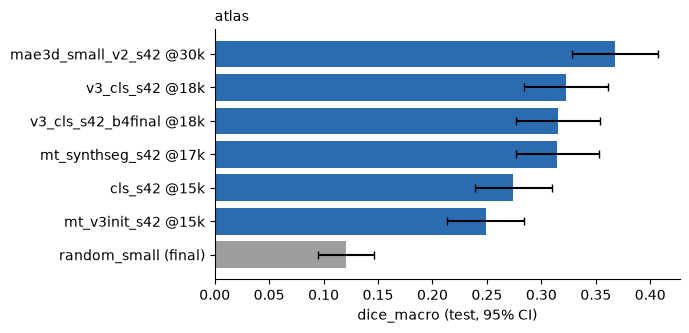

#### `brats2023_gli`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,mae3d_small_v2_s42 @30k,"0.798 [0.780, 0.813]",+0.012,tok_unet3d,val,88%,
1,mt_synthseg_s42 @17k,"0.797 [0.779, 0.812]",+0.011,tok_unet3d,val,88%,labels
2,mt_nolabels_s42 @18k,"0.791 [0.774, 0.805]",+0.004,tok_unet3d,val,88%,labels
3,random_small (final),"0.786 [0.766, 0.803]",+0.000,tok_unet3d,val,88%,
4,mt_v3init_s42 @15k,"0.784 [0.767, 0.800]",-0.002,tok_unet3d,val,88%,labels
5,v3_cls_s42 @18k,"0.779 [0.763, 0.794]",-0.007,tok_unet3d,val,88%,


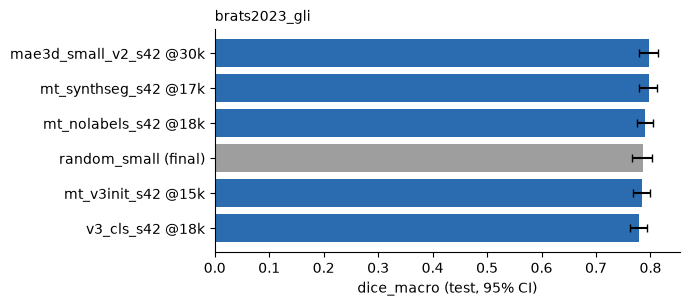

#### `brats2023_men`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_nolabels_s42 @18k,"0.679 [0.634, 0.721]",+0.067,tok_unet3d,val,94%,labels
1,mt_synthseg_s42 @17k,"0.648 [0.600, 0.693]",+0.036,tok_unet3d,val,94%,labels
2,mt_v3init_s42 @15k,"0.648 [0.600, 0.697]",+0.036,tok_unet3d,val,94%,labels
3,mae3d_small_v2_s42 @30k,"0.639 [0.589, 0.683]",+0.027,tok_unet3d,val,94%,
4,v3_cls_s42 @18k,"0.613 [0.564, 0.663]",+0.001,tok_unet3d,val,94%,
5,random_small (final),"0.612 [0.561, 0.660]",+0.000,tok_unet3d,val,94%,


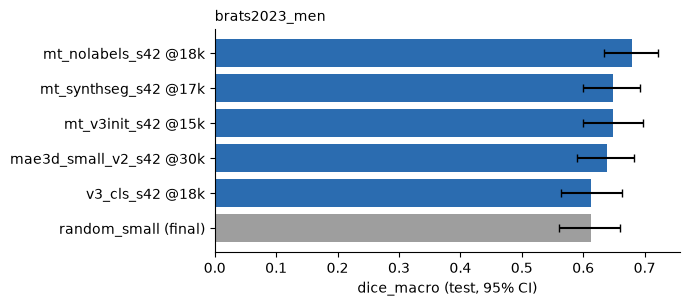

#### `brats2023_ped`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_synthseg_s42 @17k,"0.613 [0.521, 0.700]",+0.049,tok_unet3d,val,100%,labels
1,mae3d_small_v2_s42 @30k,"0.604 [0.515, 0.689]",+0.040,tok_unet3d,val,100%,
2,mt_v3init_s42 @15k,"0.594 [0.502, 0.686]",+0.030,tok_unet3d,val,100%,labels
3,v3_cls_s42 @18k,"0.575 [0.480, 0.665]",+0.011,tok_unet3d,val,100%,
4,random_small (final),"0.564 [0.464, 0.656]",+0.000,tok_unet3d,val,100%,


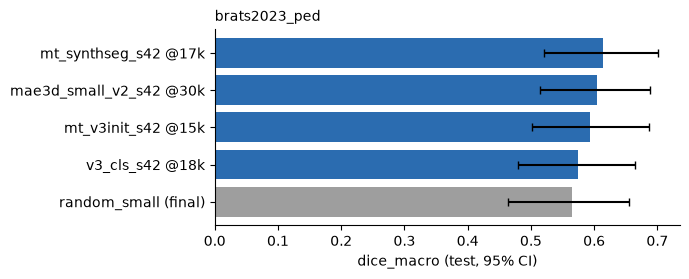

#### `brats2024_gli`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,mae3d_small_v2_s42 @30k,"0.453 [0.459, 0.499]",+0.032,tok_unet3d,val,45%,
1,mt_synthseg_s42 @17k,"0.430 [0.441, 0.479]",+0.009,tok_unet3d,val,45%,labels
2,mt_v3init_s42 @15k,"0.428 [0.436, 0.477]",+0.007,tok_unet3d,val,45%,labels
3,v3_cls_s42 @18k,"0.421 [0.431, 0.472]",+0.000,tok_unet3d,val,45%,
4,random_small (final),"0.421 [0.428, 0.470]",+0.000,tok_unet3d,val,45%,
5,mt_nolabels_s42 @18k,"0.393 [0.403, 0.442]",-0.028,tok_unet3d,val,45%,labels


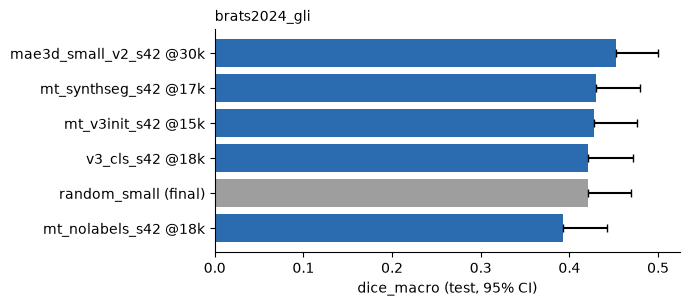

#### `instance`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,v3_cls_s42 @18k,"0.465 [0.323, 0.607]",+0.006,tok_unet3d,val,0%,
1,random_small (final),"0.459 [0.292, 0.609]",+0.000,tok_unet3d,val,0%,
2,mae3d_small_v2_s42 @30k,"0.422 [0.280, 0.558]",-0.036,tok_unet3d,val,0%,


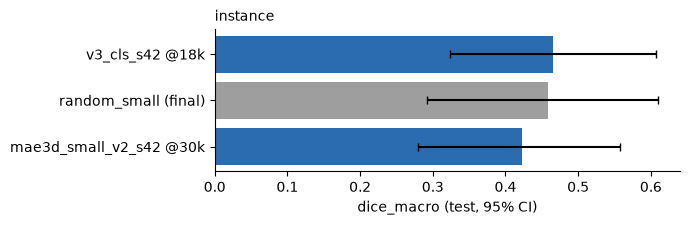

#### `isles22`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,mae3d_small_v2_s42 @30k,"0.480 [0.398, 0.562]",+0.066,tok_unet3d,val,0%,
1,v3_cls_s42 @18k,"0.466 [0.382, 0.550]",+0.053,tok_unet3d,val,0%,
2,mt_synthseg_s42 @17k,"0.464 [0.379, 0.551]",+0.051,tok_unet3d,val,0%,
3,mt_v3init_s42 @15k,"0.414 [0.330, 0.499]",+0.000,tok_unet3d,val,0%,
4,random_small (final),"0.413 [0.320, 0.507]",+0.000,tok_unet3d,val,0%,


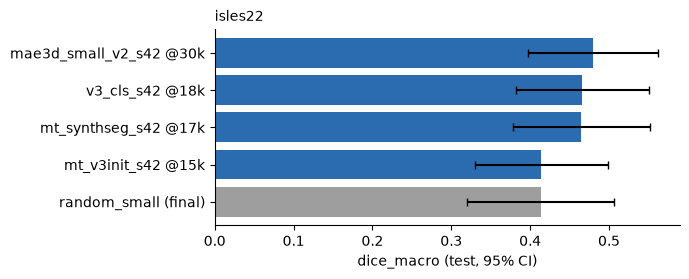

#### `isles24`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,mt_synthseg_s42 @17k,"0.162 [0.080, 0.255]",+0.032,tok_unet3d,val,0%,
1,v3_cls_s42 @18k,"0.150 [0.077, 0.243]",+0.021,tok_unet3d,val,0%,
2,mae3d_small_v2_s42 @30k,"0.136 [0.060, 0.226]",+0.006,tok_unet3d,val,0%,
3,random_small (final),"0.130 [0.073, 0.200]",+0.000,tok_unet3d,val,0%,


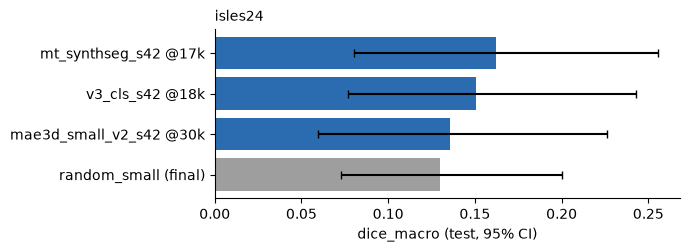

#### `ms3seg`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,v3_cls_s42 @18k,"0.553 [0.534, 0.574]",+0.007,tok_unet3d,val,0%,
1,random_small (final),"0.546 [0.521, 0.571]",+0.000,tok_unet3d,val,0%,


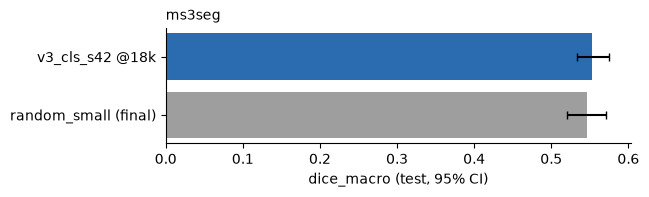

#### `seg_cq500`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,v3_cls_s42 @16k,"0.278 [0.124, 0.446]",+0.141,tok_unet3d,val,0%,
1,mt_v3init_s42 @15k,"0.256 [0.106, 0.428]",+0.119,tok_unet3d,val,0%,task
2,cls_s42 @15k,"0.253 [0.092, 0.435]",+0.115,tok_unet3d,val,0%,
3,mt_synthseg_s42 @17k,"0.240 [0.093, 0.422]",+0.103,tok_unet3d,val,0%,task
4,none_s42 @15k,"0.223 [0.069, 0.409]",+0.086,tok_unet3d,val,0%,
5,v3_cls_s42 @18k,"0.201 [0.079, 0.347]",+0.064,tok_unet3d,val,0%,
6,mae3d_small_v2_s42 @30k,"0.196 [0.084, 0.327]",+0.058,tok_unet3d,val,0%,
7,cls_reg4_s42 @15k,"0.175 [0.050, 0.345]",+0.038,tok_unet3d,val,0%,
8,v2_cls_s42 @16k,"0.172 [0.050, 0.320]",+0.034,tok_unet3d,val,0%,
9,mt_nolabels_s42 @18k,"0.171 [0.055, 0.307]",+0.033,tok_unet3d,val,0%,task


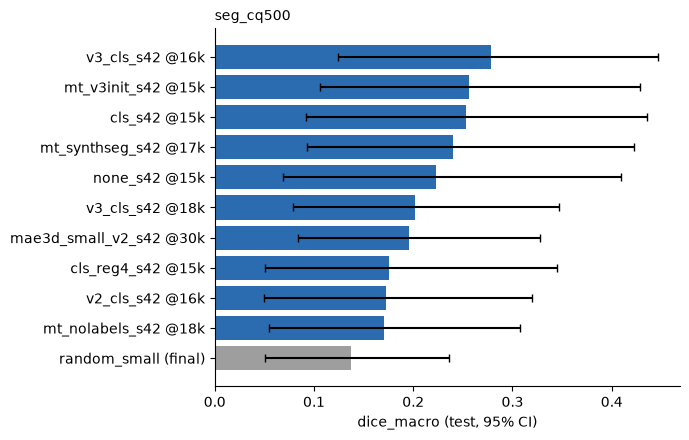

#### `valdo_cmb`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,random_small (final),"0.000 [0.000, 0.000]",+0.000,tok_unet3d,val,0%,
1,v3_cls_s42 @18k,"0.000 [0.000, 0.000]",+0.000,tok_unet3d,val,0%,


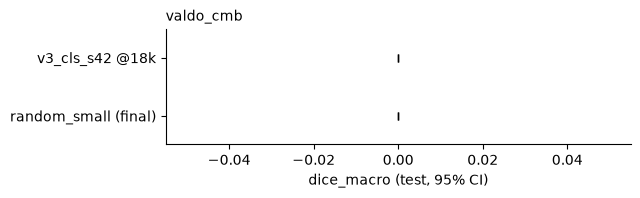

#### `valdo_lacunes`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,random_small (final),"0.000 [0.000, 0.000]",+0.000,tok_unet3d,val,0%,
1,v3_cls_s42 @18k,"0.000 [0.000, 0.000]",+0.000,tok_unet3d,val,0%,


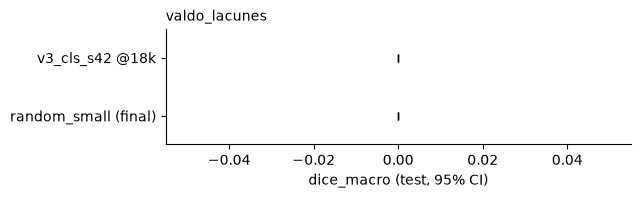

#### `wmh`

,model,dice_macro,Δ random,head,picked on,pretrain overlap,label-seen
0,v3_cls_s42_b4final @18k,"0.535 [0.478, 0.588]",+0.013,tok_unet3d,val,0%,
1,mt_synthseg_s42 @17k,"0.525 [0.467, 0.577]",+0.003,tok_unet3d,val,0%,
2,random_small (final),"0.522 [0.461, 0.576]",+0.000,tok_unet3d,val,0%,
3,mt_v3init_s42 @15k,"0.520 [0.464, 0.571]",-0.002,tok_unet3d,val,0%,
4,mae3d_small_v2_s42 @30k,"0.478 [0.414, 0.537]",-0.044,tok_unet3d,val,0%,
5,v3_cls_s42 @18k,"0.428 [0.365, 0.486]",-0.094,tok_unet3d,val,0%,


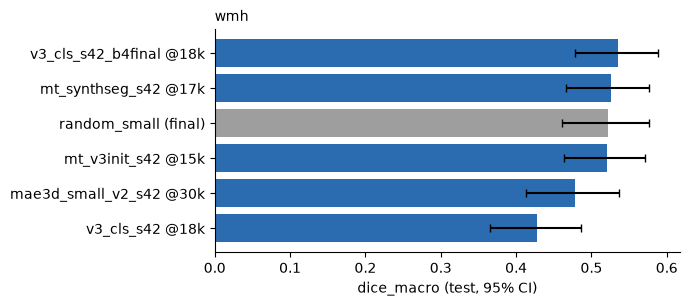

In [8]:
for group in rv.GROUP_ORDER:
    tasks = sorted(rep.loc[rep.group == group, "task"].unique())
    if not tasks:
        continue
    display(Markdown(f"### {group}"))
    for task in tasks:
        display(Markdown(f"#### `{task}`"))
        display(rv.task_table(rep, task))
        rv.plot_task(rep, task)
        plt.show()

## Drill-down: every head on one task

Check that the validation-picked head is not a fluke (val vs test per head).

In [10]:
rv.all_heads("cq500")

,model,task,head,view,metric,val,test,ci_lo,ci_hi,n_test,pretrain_overlap,finished_utc
0,cls_s42 @15k,cq500,cls_logreg,cls,auc_ovr_macro,0.827618,0.862777,0.811837,0.907244,70,0.0,2026-10-19T01:59:52+00:00
1,cls_s42 @15k,cq500,tok_conv,tokens,auc_ovr_macro,0.809566,0.810736,0.736596,0.871768,70,0.0,2026-10-19T01:59:52+00:00
2,cls_s42 @15k,cq500,plane_logreg,plane,auc_ovr_macro,0.768685,0.769720,0.704055,0.830803,70,0.0,2026-10-19T01:59:52+00:00
3,cls_s42 @15k,cq500,pca_global_logreg,global,auc_ovr_macro,0.740577,0.656567,0.527889,0.774599,70,0.0,2026-10-19T01:59:52+00:00
4,cls_s42 @15k,cq500,grid_logreg,grid,auc_ovr_macro,0.697814,0.764150,0.697344,0.816178,70,0.0,2026-10-19T01:59:52+00:00
5,random_small (final),cq500,tok_conv,tokens,auc_ovr_macro,0.783753,0.791044,0.715497,0.857477,70,0.0,2026-10-18T17:27:20+00:00
6,random_small (final),cq500,grid_logreg,grid,auc_ovr_macro,0.683114,0.746497,0.677732,0.805859,70,0.0,2026-10-18T17:27:20+00:00
7,random_small (final),cq500,plane_logreg,plane,auc_ovr_macro,0.671578,0.684772,0.606460,0.758997,70,0.0,2026-10-18T17:27:20+00:00
8,random_small (final),cq500,pca_global_logreg,global,auc_ovr_macro,0.593801,0.629000,0.529561,0.719476,70,0.0,2026-10-18T17:27:20+00:00


## Token probes (lesion / fingerprint / location)

In [ ]:
rv.probes()